In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("dataset-2.csv")

In [8]:
df.head(5)

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,5634,3392,1,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,26.822620,265.0,No,49.574949,21.46538,High_spent_Small_value_payments,312.494089,Good
1,5635,3392,2,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.944960,266.0,No,49.574949,21.46538,Low_spent_Large_value_payments,284.629162,Good
2,5636,3392,3,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,28.609352,267.0,No,49.574949,21.46538,Low_spent_Medium_value_payments,331.209863,Good
3,5637,3392,4,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.377862,268.0,No,49.574949,21.46538,Low_spent_Small_value_payments,223.451310,Good
4,5638,3392,5,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,24.797347,269.0,No,49.574949,21.46538,High_spent_Medium_value_payments,341.489231,Good


In [9]:
df.columns

Index(['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation',
       'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts',
       'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan',
       'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
       'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt',
       'Credit_Utilization_Ratio', 'Credit_History_Age',
       'Payment_of_Min_Amount', 'Total_EMI_per_month',
       'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance',
       'Credit_Score'],
      dtype='str')

In [10]:
df.shape

(100000, 28)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  int64  
 1   Customer_ID               100000 non-null  int64  
 2   Month                     100000 non-null  int64  
 3   Name                      100000 non-null  str    
 4   Age                       100000 non-null  float64
 5   SSN                       100000 non-null  float64
 6   Occupation                100000 non-null  str    
 7   Annual_Income             100000 non-null  float64
 8   Monthly_Inhand_Salary     100000 non-null  float64
 9   Num_Bank_Accounts         100000 non-null  float64
 10  Num_Credit_Card           100000 non-null  float64
 11  Interest_Rate             100000 non-null  float64
 12  Num_of_Loan               100000 non-null  float64
 13  Type_of_Loan              100000 non-null  str    
 14  

In [12]:

# Check missing values in each column
print(df.isnull().sum())

ID                          0
Customer_ID                 0
Month                       0
Name                        0
Age                         0
SSN                         0
Occupation                  0
Annual_Income               0
Monthly_Inhand_Salary       0
Num_Bank_Accounts           0
Num_Credit_Card             0
Interest_Rate               0
Num_of_Loan                 0
Type_of_Loan                0
Delay_from_due_date         0
Num_of_Delayed_Payment      0
Changed_Credit_Limit        0
Num_Credit_Inquiries        0
Credit_Mix                  0
Outstanding_Debt            0
Credit_Utilization_Ratio    0
Credit_History_Age          0
Payment_of_Min_Amount       0
Total_EMI_per_month         0
Amount_invested_monthly     0
Payment_Behaviour           0
Monthly_Balance             0
Credit_Score                0
dtype: int64


In [13]:

print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [14]:
print(df.select_dtypes(include=["number"]).columns)

Index(['ID', 'Customer_ID', 'Month', 'Age', 'SSN', 'Annual_Income',
       'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card',
       'Interest_Rate', 'Num_of_Loan', 'Delay_from_due_date',
       'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
       'Num_Credit_Inquiries', 'Outstanding_Debt', 'Credit_Utilization_Ratio',
       'Credit_History_Age', 'Total_EMI_per_month', 'Amount_invested_monthly',
       'Monthly_Balance'],
      dtype='str')


In [15]:

print(df["Credit_Score"].value_counts())

Credit_Score
Standard    53174
Poor        28998
Good        17828
Name: count, dtype: int64


<ipython-input-16-f2380c0b9709>:9: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("Distribution of credit Score", dpi=300, bbox_inches="tight")
<ipython-input-16-f2380c0b9709>:9: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("Distribution of credit Score", dpi=300, bbox_inches="tight")


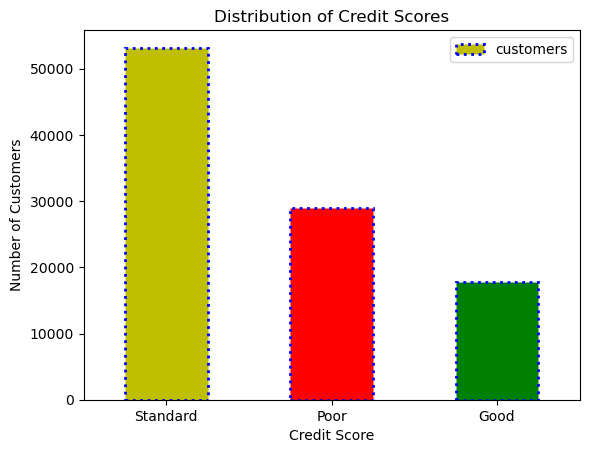

In [16]:

import matplotlib.pyplot as plt
c =['y', 'r', 'g']
df["Credit_Score"].value_counts().plot(kind="bar", color = c, edgecolor = "b", linewidth= 2, linestyle= ":", label="customers")
plt.title("Distribution of Credit Scores")
plt.xlabel("Credit Score")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend()
plt.savefig("Distribution of credit Score", dpi=300, bbox_inches="tight")
plt.show()


In [17]:
debt_analysis = df.groupby("Credit_Score")["Outstanding_Debt"].mean()

print(debt_analysis)

Credit_Score
Good         801.256324
Poor        2081.473157
Standard    1278.419552
Name: Outstanding_Debt, dtype: float64


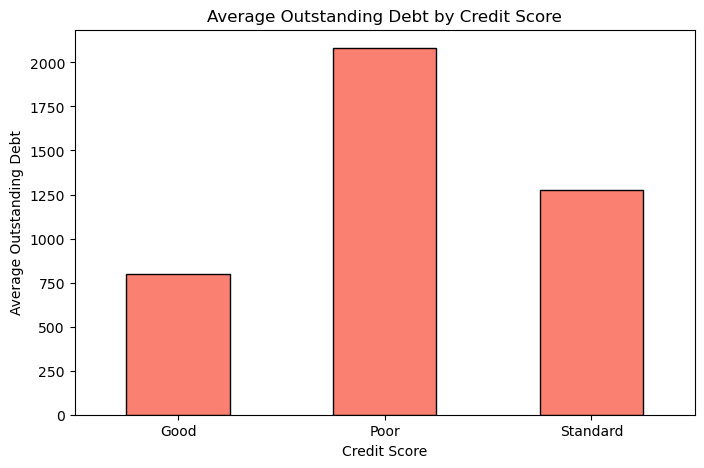

In [20]:
debt_analysis.plot(
    kind="bar",
    color="salmon",
    edgecolor="black",
    figsize=(8, 5)
)

plt.title("Average Outstanding Debt by Credit Score")
plt.xlabel("Credit Score")
plt.ylabel("Average Outstanding Debt")
plt.xticks(rotation=0)
plt.show()

In [21]:
delay_analysis = df.groupby("Credit_Score")["Delay_from_due_date"].mean()

print(delay_analysis)

Credit_Score
Good        10.958997
Poor        29.728809
Standard    19.759431
Name: Delay_from_due_date, dtype: float64


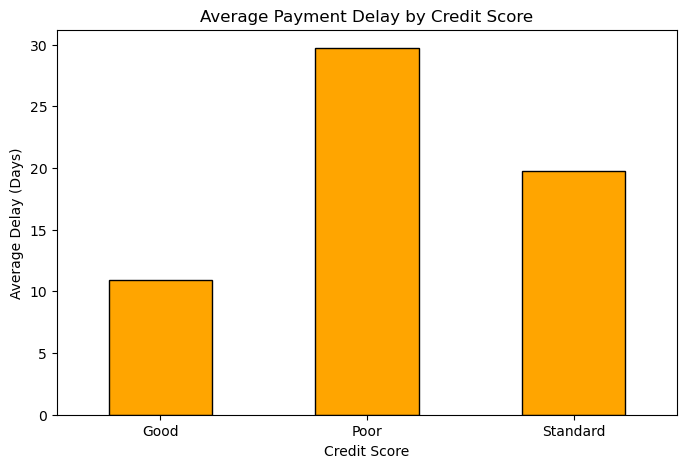

In [22]:

delay_analysis.plot(
    kind="bar",
    color="orange",
    edgecolor="black",
    figsize=(8, 5)
)

plt.title("Average Payment Delay by Credit Score")
plt.xlabel("Credit Score")
plt.ylabel("Average Delay (Days)")
plt.xticks(rotation=0)
plt.show()

In [23]:
pd.crosstab(df["Credit_Mix"], df["Credit_Score"])

Credit_Score,Good,Poor,Standard
Credit_Mix,,,
Bad,351,14289,9128
Good,14848,4851,10685
Standard,2629,9858,33361


In [24]:
credit_mix_percentage = pd.crosstab(
    df["Credit_Mix"],
    df["Credit_Score"],
    normalize="index"
) * 100

print(credit_mix_percentage.round(2))

Credit_Score   Good   Poor  Standard
Credit_Mix                          
Bad            1.48  60.12     38.40
Good          48.87  15.97     35.17
Standard       5.73  21.50     72.76


<ipython-input-25-1817801becdf>:14: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("Credit mix vs credit score.png", dpi=300, bbox_inches="tight")
<ipython-input-25-1817801becdf>:14: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("Credit mix vs credit score.png", dpi=300, bbox_inches="tight")


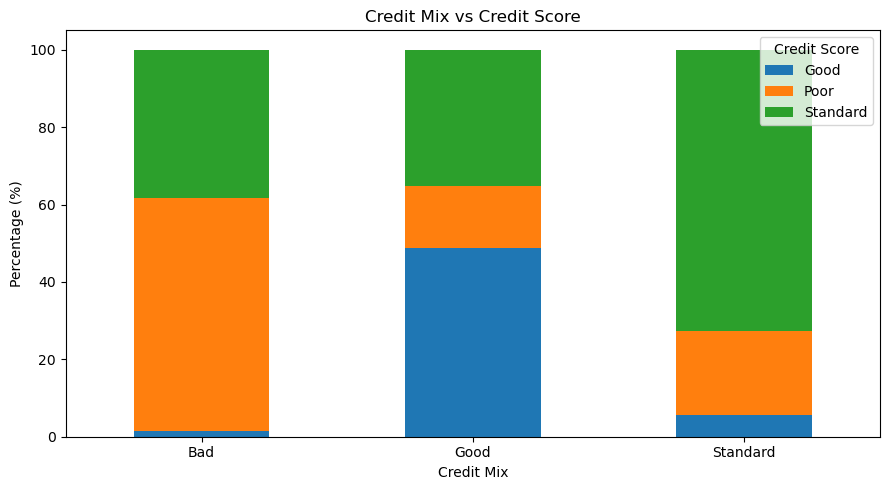

In [25]:
credit_mix_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Credit Mix vs Credit Score")
plt.xlabel("Credit Mix")
plt.ylabel("Percentage (%)")

plt.xticks(rotation=0)
plt.legend(title="Credit Score")
plt.tight_layout()
plt.savefig("Credit mix vs credit score.png", dpi=300, bbox_inches="tight")
plt.show()


In [26]:

income_by_score = df.groupby("Credit_Score")["Annual_Income"].mean()

print(income_by_score)


Credit_Score
Good        65203.672105
Poor        40584.515325
Standard    50987.164840
Name: Annual_Income, dtype: float64


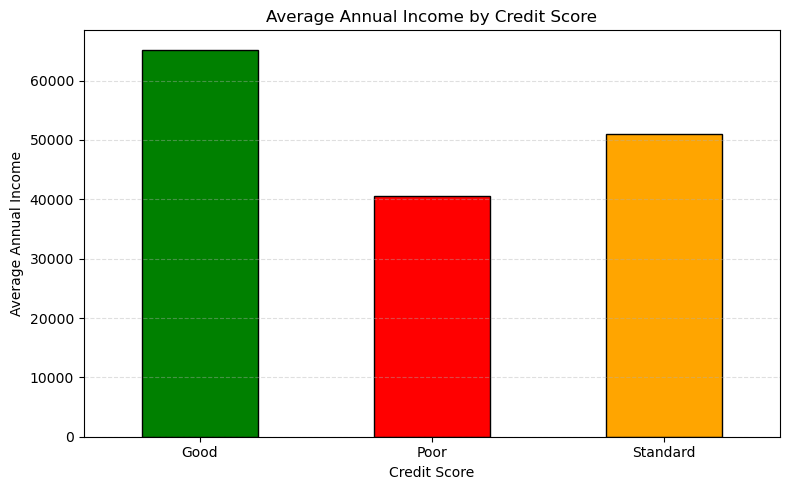

In [27]:

import matplotlib.pyplot as plt

income_by_score.plot(
    kind="bar",
    color=["green", "red", "orange"],
    edgecolor="black",
    figsize=(8, 5)
)

plt.title("Average Annual Income by Credit Score")
plt.xlabel("Credit Score")
plt.ylabel("Average Annual Income")

plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


In [28]:

interest_analysis = df.groupby("Credit_Score")["Interest_Rate"].mean()

print(interest_analysis)


Credit_Score
Good         7.662329
Poor        20.187116
Standard    13.751420
Name: Interest_Rate, dtype: float64


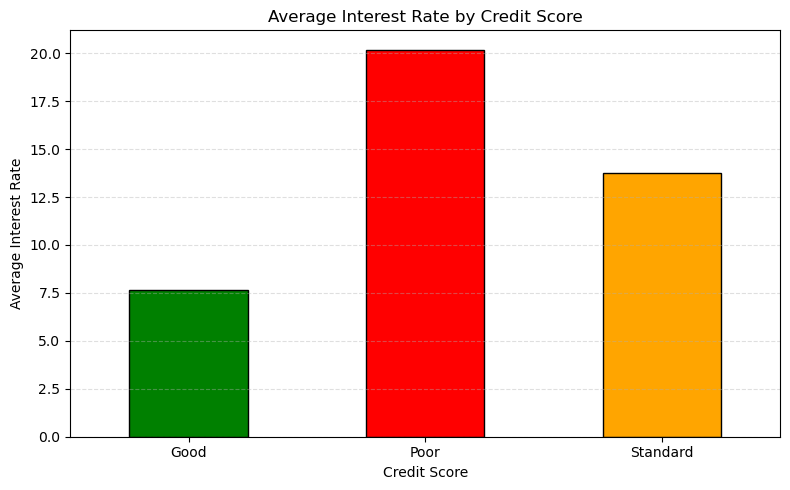

In [29]:

import matplotlib.pyplot as plt

interest_analysis.plot(
    kind="bar",
    color=["green", "red", "orange"],
    edgecolor="black",
    figsize=(8, 5)
)

plt.title("Average Interest Rate by Credit Score")
plt.xlabel("Credit Score")
plt.ylabel("Average Interest Rate")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [30]:

utilization_analysis = df.groupby("Credit_Score")["Credit_Utilization_Ratio"].mean()

print(utilization_analysis)


Credit_Score
Good        32.686107
Poor        31.986146
Standard    32.313820
Name: Credit_Utilization_Ratio, dtype: float64


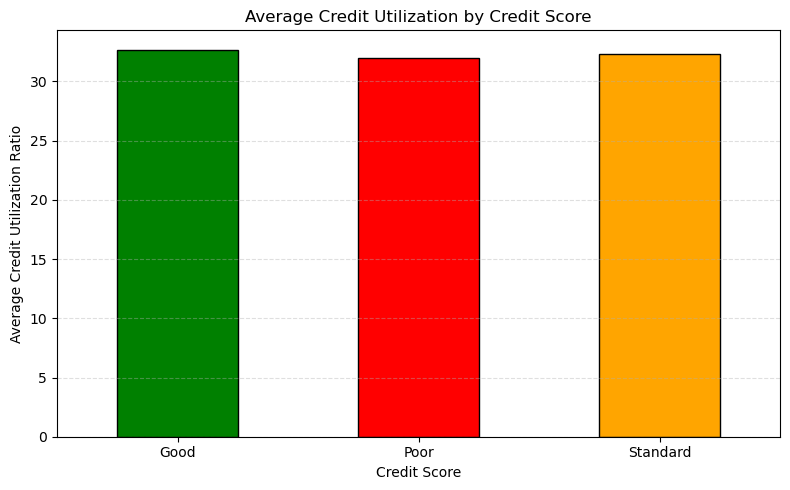

In [31]:

import matplotlib.pyplot as plt

utilization_analysis.plot(
    kind="bar",
    color=["green", "red", "orange"],
    edgecolor="black",
    figsize=(8, 5)
)

plt.title("Average Credit Utilization by Credit Score")
plt.xlabel("Credit Score")
plt.ylabel("Average Credit Utilization Ratio")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


In [32]:

numeric_df = df.select_dtypes(include="number")

correlation_matrix = numeric_df.corr()

print(correlation_matrix["Credit_Utilization_Ratio"].sort_values())

Num_of_Loan                -0.100469
Num_Credit_Inquiries       -0.076943
Interest_Rate              -0.075700
Num_of_Delayed_Payment     -0.073774
Num_Bank_Accounts          -0.071783
Outstanding_Debt           -0.071165
Delay_from_due_date        -0.063823
Num_Credit_Card            -0.055249
Changed_Credit_Limit       -0.047903
ID                         -0.005402
Customer_ID                -0.002174
Month                       0.002440
SSN                         0.002653
Total_EMI_per_month         0.022365
Age                         0.025492
Credit_History_Age          0.073237
Amount_invested_monthly     0.135089
Annual_Income               0.175930
Monthly_Inhand_Salary       0.176092
Monthly_Balance             0.224729
Credit_Utilization_Ratio    1.000000
Name: Credit_Utilization_Ratio, dtype: float64


<ipython-input-33-13680eb3d3e4>:43: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("Correlation Heatmap of Financial Features.png", dpi=300, bbox_inches="tight")
<ipython-input-33-13680eb3d3e4>:43: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("Correlation Heatmap of Financial Features.png", dpi=300, bbox_inches="tight")


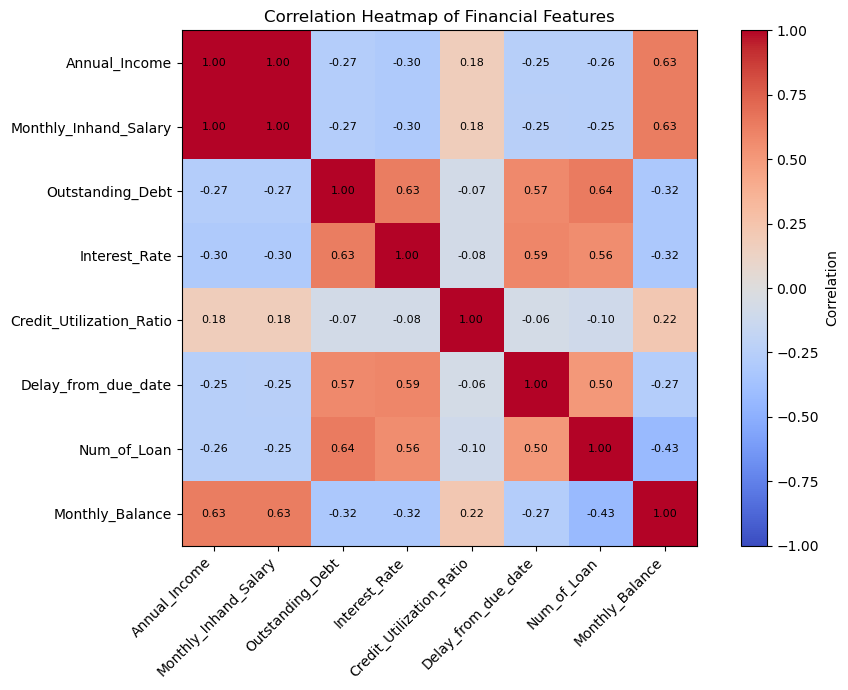

In [33]:


import matplotlib.pyplot as plt
import numpy as np

selected_columns = [
    "Annual_Income",
    "Monthly_Inhand_Salary",
    "Outstanding_Debt",
    "Interest_Rate",
    "Credit_Utilization_Ratio",
    "Delay_from_due_date",
    "Num_of_Loan",
    "Monthly_Balance"
]

correlation_matrix = df[selected_columns].corr()

plt.figure(figsize=(10, 7))

plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(selected_columns)),
    selected_columns,
    rotation=45,
    ha="right"
)

plt.yticks(range(len(selected_columns)), selected_columns)

for i in range(len(selected_columns)):
    for j in range(len(selected_columns)):
        plt.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.title("Correlation Heatmap of Financial Features")
plt.tight_layout()
plt.savefig("Correlation Heatmap of Financial Features.png", dpi=300, bbox_inches="tight")
plt.show()


<ipython-input-34-1884618f50aa>:10: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("Outstanding Debt vs Credit Score.png", dpi=300, bbox_inches="tight")
<ipython-input-34-1884618f50aa>:10: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("Outstanding Debt vs Credit Score.png", dpi=300, bbox_inches="tight")


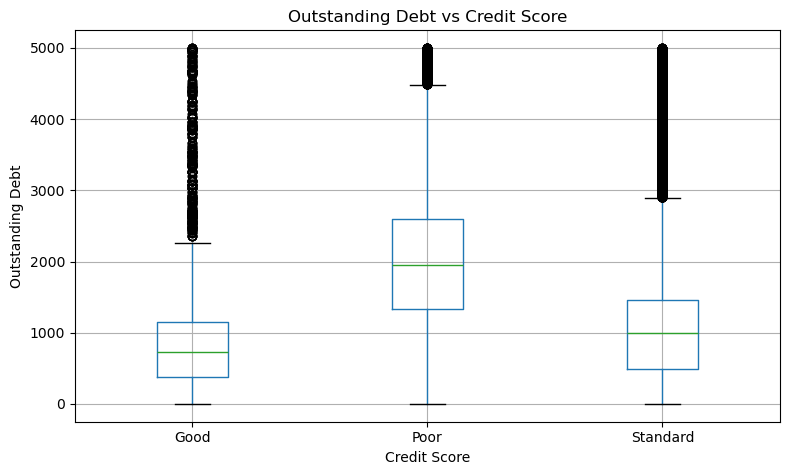

In [34]:
import matplotlib.pyplot as plt

df.boxplot(column="Outstanding_Debt", by="Credit_Score", figsize=(8, 5))

plt.title("Outstanding Debt vs Credit Score")
plt.suptitle("")
plt.xlabel("Credit Score")
plt.ylabel("Outstanding Debt")
plt.tight_layout()
plt.savefig("Outstanding Debt vs Credit Score.png", dpi=300, bbox_inches="tight")
plt.show()

<ipython-input-35-f9f05a9012cd>:10: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("Payment Delay vs Credit Score.png", dpi=300, bbox_inches="tight")
<ipython-input-35-f9f05a9012cd>:10: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("Payment Delay vs Credit Score.png", dpi=300, bbox_inches="tight")


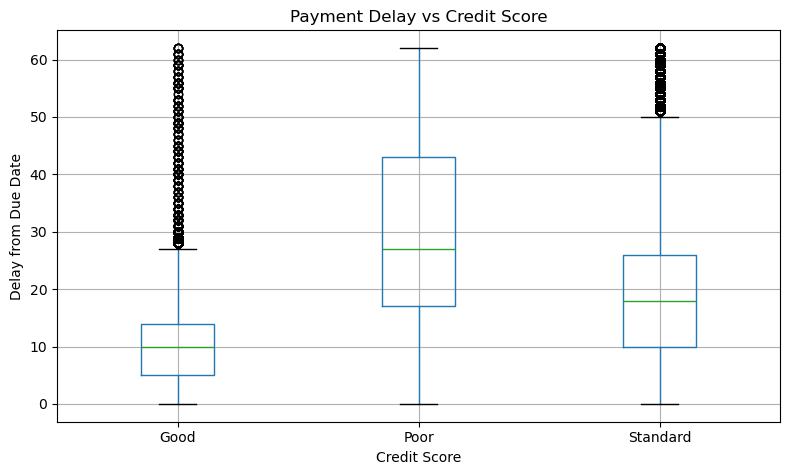

In [35]:
import matplotlib.pyplot as plt

df.boxplot(column="Delay_from_due_date", by="Credit_Score", figsize=(8, 5))

plt.title("Payment Delay vs Credit Score")
plt.suptitle("")
plt.xlabel("Credit Score")
plt.ylabel("Delay from Due Date")
plt.tight_layout()
plt.savefig("Payment Delay vs Credit Score.png", dpi=300, bbox_inches="tight")
plt.show()

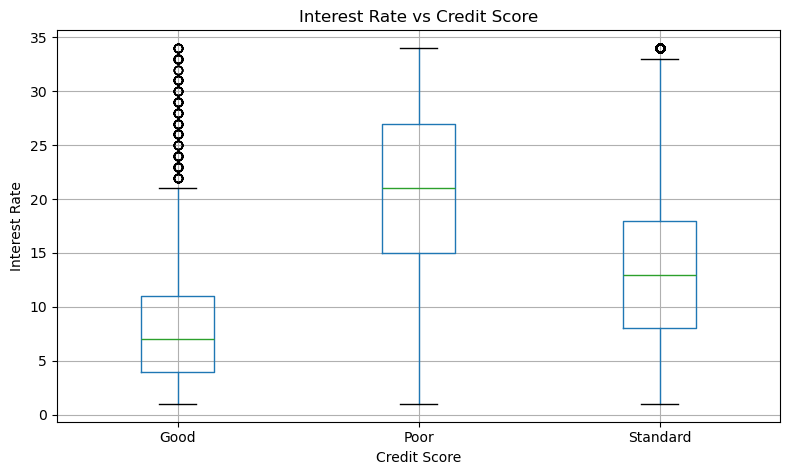

<Figure size 640x480 with 0 Axes>

In [36]:
import matplotlib.pyplot as plt

df.boxplot(column="Interest_Rate", by="Credit_Score", figsize=(8, 5))

plt.title("Interest Rate vs Credit Score")
plt.suptitle("")
plt.xlabel("Credit Score")
plt.ylabel("Interest Rate")
plt.tight_layout()
plt.show()
plt.savefig("interest Rate vs Credit Score.png", dpi=300, bbox_inches="tight")

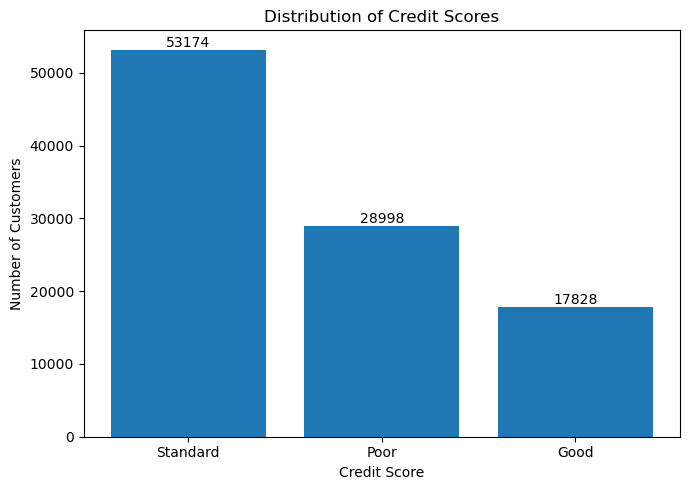

In [37]:
import matplotlib.pyplot as plt

credit_counts = df["Credit_Score"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(credit_counts.index, credit_counts.values)

plt.title("Distribution of Credit Scores")
plt.xlabel("Credit Score")
plt.ylabel("Number of Customers")

for i in range(len(credit_counts)):
    plt.text(i, credit_counts.values[i], str(credit_counts.values[i]),
             ha="center", va="bottom")

plt.tight_layout()
plt.show()

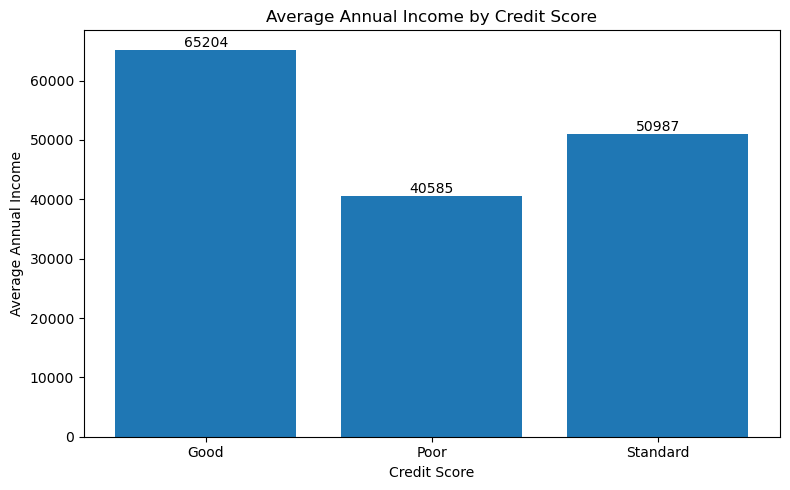

In [38]:
import matplotlib.pyplot as plt

income_by_score = df.groupby("Credit_Score")["Annual_Income"].mean()

plt.figure(figsize=(8, 5))
plt.bar(income_by_score.index, income_by_score.values)

plt.title("Average Annual Income by Credit Score")
plt.xlabel("Credit Score")
plt.ylabel("Average Annual Income")

for i in range(len(income_by_score)):
    plt.text(
        i,
        income_by_score.values[i],
        f"{income_by_score.values[i]:.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [39]:
print("Credit Score Distribution:")
print(df["Credit_Score"].value_counts())

print("\nAverage Annual Income:")
print(df.groupby("Credit_Score")["Annual_Income"].mean().round(2))

print("\nAverage Outstanding Debt:")
print(df.groupby("Credit_Score")["Outstanding_Debt"].mean().round(2))

print("\nAverage Payment Delay:")
print(df.groupby("Credit_Score")["Delay_from_due_date"].mean().round(2))

print("\nAverage Interest Rate:")
print(df.groupby("Credit_Score")["Interest_Rate"].mean().round(2))

Credit Score Distribution:
Credit_Score
Standard    53174
Poor        28998
Good        17828
Name: count, dtype: int64

Average Annual Income:
Credit_Score
Good        65203.67
Poor        40584.52
Standard    50987.16
Name: Annual_Income, dtype: float64

Average Outstanding Debt:
Credit_Score
Good         801.26
Poor        2081.47
Standard    1278.42
Name: Outstanding_Debt, dtype: float64

Average Payment Delay:
Credit_Score
Good        10.96
Poor        29.73
Standard    19.76
Name: Delay_from_due_date, dtype: float64

Average Interest Rate:
Credit_Score
Good         7.66
Poor        20.19
Standard    13.75
Name: Interest_Rate, dtype: float64


In [40]:
print(df.columns.tolist())

['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance', 'Credit_Score']


In [41]:
print(df["Credit_Score"].value_counts())
print(df.dtypes)

Credit_Score
Standard    53174
Poor        28998
Good        17828
Name: count, dtype: int64
ID                            int64
Customer_ID                   int64
Month                         int64
Name                            str
Age                         float64
SSN                         float64
Occupation                      str
Annual_Income               float64
Monthly_Inhand_Salary       float64
Num_Bank_Accounts           float64
Num_Credit_Card             float64
Interest_Rate               float64
Num_of_Loan                 float64
Type_of_Loan                    str
Delay_from_due_date         float64
Num_of_Delayed_Payment      float64
Changed_Credit_Limit        float64
Num_Credit_Inquiries        float64
Credit_Mix                      str
Outstanding_Debt            float64
Credit_Utilization_Ratio    float64
Credit_History_Age          float64
Payment_of_Min_Amount           str
Total_EMI_per_month         float64
Amount_invested_monthly     float64
Payment

In [42]:
# Target variable
y = df["Credit_Score"]

# Unnecessary identification columns remove karna
columns_to_drop = [
    "ID",
    "Customer_ID",
    "Name",
    "SSN"
]

X = df.drop(columns=columns_to_drop + ["Credit_Score"], errors="ignore")

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget categories:")
print(y.value_counts())

Features shape: (100000, 23)
Target shape: (100000,)

Target categories:
Credit_Score
Standard    53174
Poor        28998
Good        17828
Name: count, dtype: int64


In [43]:
# X mein text/categorical columns identify karna
categorical_columns = X.select_dtypes(include=["object"]).columns

print("Categorical columns:")
print(categorical_columns.tolist())

print("\nTotal categorical columns:", len(categorical_columns))

<ipython-input-43-2335f0fd624a>:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include=["object"]).columns


Categorical columns:
['Occupation', 'Type_of_Loan', 'Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour']

Total categorical columns: 5


In [44]:
for col in categorical_columns:
    print(f"\n{col}:")
    print(X[col].nunique(), "unique values")


Occupation:
15 unique values

Type_of_Loan:
6261 unique values

Credit_Mix:
3 unique values

Payment_of_Min_Amount:
3 unique values

Payment_Behaviour:
6 unique values


In [45]:
categorical_columns = X.select_dtypes(include=["object", "str"]).columns

print("Categorical columns:")
print(categorical_columns.tolist())

print("\nTotal categorical columns:", len(categorical_columns))

Categorical columns:
['Occupation', 'Type_of_Loan', 'Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour']

Total categorical columns: 5


In [46]:
for col in categorical_columns:
    print(f"\n{col}:")
    print(X[col].nunique(), "unique values")


Occupation:
15 unique values

Type_of_Loan:
6261 unique values

Credit_Mix:
3 unique values

Payment_of_Min_Amount:
3 unique values

Payment_Behaviour:
6 unique values


In [47]:
for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(X[col].value_counts().head(10))


--- Occupation ---
Occupation
Lawyer           7096
Engineer         6864
Architect        6824
Mechanic         6776
Scientist        6744
Accountant       6744
Developer        6720
Media_Manager    6720
Teacher          6672
Entrepreneur     6648
Name: count, dtype: int64

--- Type_of_Loan ---
Type_of_Loan
No Data                    11408
Not Specified               1408
Credit-Builder Loan         1280
Personal Loan               1272
Debt Consolidation Loan     1264
Student Loan                1240
Payday Loan                 1200
Mortgage Loan               1176
Auto Loan                   1152
Home Equity Loan            1136
Name: count, dtype: int64

--- Credit_Mix ---
Credit_Mix
Standard    45848
Good        30384
Bad         23768
Name: count, dtype: int64

--- Payment_of_Min_Amount ---
Payment_of_Min_Amount
Yes    52326
No     35667
NM     12007
Name: count, dtype: int64

--- Payment_Behaviour ---
Payment_Behaviour
Low_spent_Small_value_payments      28616
High_spent_Mediu

In [50]:
y = df["Credit_Score"]

columns_to_drop = [
    "ID",
    "Customer_ID",
    "Name",
    "SSN"
]

X = df.drop(
    columns=columns_to_drop + ["Credit_Score"],
    errors="ignore"
)

categorical_columns = X.select_dtypes(
    include=["object", "str"]
).columns

In [54]:
# Remove high-cardinality column

X = X.drop(columns=["Type_of_Loan"])

# Update categorical columns

categorical_columns = X.select_dtypes(
    include=["object", "str"]
).columns

print(categorical_columns.tolist())

['Occupation', 'Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour']


In [53]:
for col in categorical_columns:
    print(
        col,
        "| Unique values:", X[col].nunique(),
        "| Data type:", X[col].dtype
    )

Occupation | Unique values: 15 | Data type: str
Type_of_Loan | Unique values: 6261 | Data type: str
Credit_Mix | Unique values: 3 | Data type: str
Payment_of_Min_Amount | Unique values: 3 | Data type: str
Payment_Behaviour | Unique values: 6 | Data type: str


In [55]:
X_encoded = pd.get_dummies(
    X,
    columns=categorical_columns,
    dtype=int
)

print("Original X shape:", X.shape)
print("Encoded X shape:", X_encoded.shape)

X_encoded.head()

Original X shape: (100000, 22)
Encoded X shape: (100000, 45)


,Month,Age,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,...,Credit_Mix_Standard,Payment_of_Min_Amount_NM,Payment_of_Min_Amount_No,Payment_of_Min_Amount_Yes,Payment_Behaviour_High_spent_Large_value_payments,Payment_Behaviour_High_spent_Medium_value_payments,Payment_Behaviour_High_spent_Small_value_payments,Payment_Behaviour_Low_spent_Large_value_payments,Payment_Behaviour_Low_spent_Medium_value_payments,Payment_Behaviour_Low_spent_Small_value_payments
0,1,23.0,19114.12,1824.843333,3.0,4.0,3.0,4.0,3.0,7.0,...,0,0,1,0,0,0,1,0,0,0
1,2,23.0,19114.12,1824.843333,3.0,4.0,3.0,4.0,3.0,4.0,...,0,0,1,0,0,0,0,1,0,0
2,3,23.0,19114.12,1824.843333,3.0,4.0,3.0,4.0,3.0,7.0,...,0,0,1,0,0,0,0,0,1,0
3,4,23.0,19114.12,1824.843333,3.0,4.0,3.0,4.0,5.0,4.0,...,0,0,1,0,0,0,0,0,0,1
4,5,23.0,19114.12,1824.843333,3.0,4.0,3.0,4.0,6.0,4.0,...,0,0,1,0,0,1,0,0,0,0


In [59]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (80000, 45)
X_test: (20000, 45)
y_train: (80000,)
y_test: (20000,)


In [61]:
from sklearn.ensemble import RandomForestClassifier

# Create model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [62]:
# Predict on test data
y_pred = model.predict(X_test)

print("First 10 Predictions:")
print(y_pred[:10])

print("\nActual Values:")
print(y_test[:10].values)

First 10 Predictions:
['Poor' 'Poor' 'Poor' 'Standard' 'Standard' 'Good' 'Standard' 'Standard'
 'Standard' 'Standard']

Actual Values:
<StringArray>
[    'Poor',     'Poor',     'Poor', 'Standard', 'Standard', 'Standard',
 'Standard', 'Standard', 'Standard', 'Standard']
Length: 10, dtype: str


In [63]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 83.035 %

Classification Report:
              precision    recall  f1-score   support

        Good       0.80      0.80      0.80      3566
        Poor       0.81      0.85      0.83      5799
    Standard       0.85      0.83      0.84     10635

    accuracy                           0.83     20000
   macro avg       0.82      0.83      0.82     20000
weighted avg       0.83      0.83      0.83     20000


Confusion Matrix:
[[2867   12  687]
 [  44 4929  826]
 [ 677 1147 8811]]


In [64]:
print("Total Records:", len(df))

print("Unique Customers:", df["Customer_ID"].nunique())

print("\nRecords per Customer:")
print(df["Customer_ID"].value_counts().head(10))

Total Records: 100000
Unique Customers: 12500

Records per Customer:
Customer_ID
3392     8
8625     8
11708    8
47249    8
7387     8
38382    8
10314    8
21511    8
16727    8
47624    8
Name: count, dtype: int64


In [65]:
from sklearn.model_selection import GroupShuffleSplit

# Identify customer groups
groups = df.loc[X_encoded.index, "Customer_ID"]

# Split customers, not individual rows
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(X_encoded, y, groups=groups)
)

# Create training and testing datasets
X_train = X_encoded.iloc[train_idx]
X_test = X_encoded.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training records:", X_train.shape)
print("Testing records:", X_test.shape)

print("Training customers:", groups.iloc[train_idx].nunique())
print("Testing customers:", groups.iloc[test_idx].nunique())

# Check customer overlap
print(
    "Common customers:",
    len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))
)

Training records: (80000, 45)
Testing records: (20000, 45)
Training customers: 10000
Testing customers: 2500
Common customers: 0


In [66]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Group-based model training completed!")

Group-based model training completed!


In [67]:
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred) * 100)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 70.60499999999999

Classification Report:
              precision    recall  f1-score   support

        Good       0.58      0.62      0.60      3563
        Poor       0.72      0.67      0.70      5813
    Standard       0.74      0.75      0.75     10624

    accuracy                           0.71     20000
   macro avg       0.68      0.68      0.68     20000
weighted avg       0.71      0.71      0.71     20000


Confusion Matrix:
[[2212   59 1292]
 [ 397 3921 1495]
 [1191 1445 7988]]


In [68]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(15))

                     Feature  Importance
12          Outstanding_Debt    0.098530
6              Interest_Rate    0.064734
14        Credit_History_Age    0.061665
8        Delay_from_due_date    0.056178
10      Changed_Credit_Limit    0.049589
17           Monthly_Balance    0.043962
35       Credit_Mix_Standard    0.042912
34           Credit_Mix_Good    0.041748
13  Credit_Utilization_Ratio    0.041007
11      Num_Credit_Inquiries    0.040225
15       Total_EMI_per_month    0.038082
5            Num_Credit_Card    0.037529
2              Annual_Income    0.037477
3      Monthly_Inhand_Salary    0.037416
16   Amount_invested_monthly    0.036999


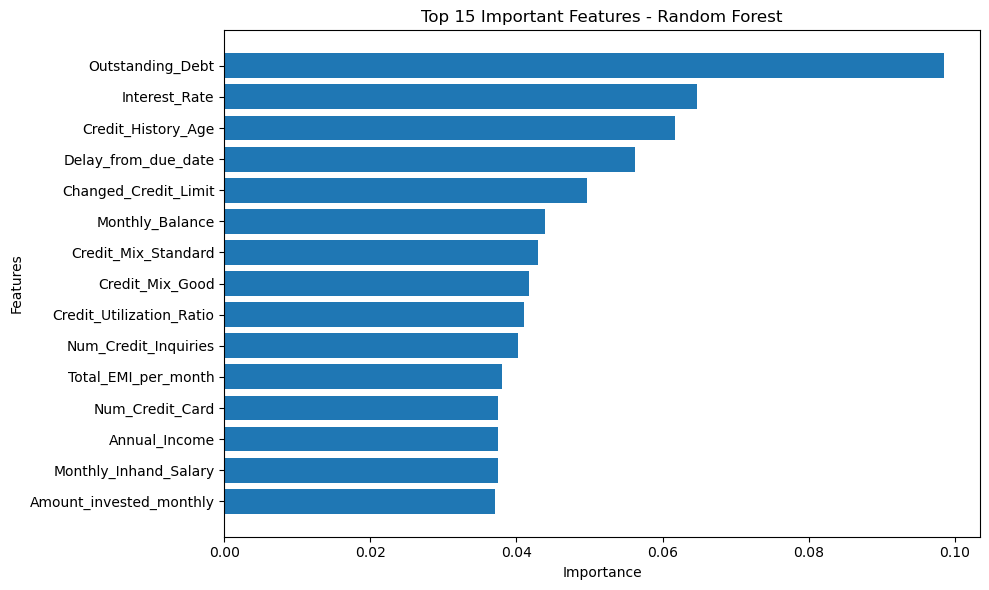

In [69]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"].head(15)[::-1],
    feature_importance["Importance"].head(15)[::-1]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Top 15 Important Features - Random Forest")

plt.tight_layout()
plt.show()


In [70]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

In [71]:
print(feature_importance.head(15))


                     Feature  Importance
12          Outstanding_Debt    0.098530
6              Interest_Rate    0.064734
14        Credit_History_Age    0.061665
8        Delay_from_due_date    0.056178
10      Changed_Credit_Limit    0.049589
17           Monthly_Balance    0.043962
35       Credit_Mix_Standard    0.042912
34           Credit_Mix_Good    0.041748
13  Credit_Utilization_Ratio    0.041007
11      Num_Credit_Inquiries    0.040225
15       Total_EMI_per_month    0.038082
5            Num_Credit_Card    0.037529
2              Annual_Income    0.037477
3      Monthly_Inhand_Salary    0.037416
16   Amount_invested_monthly    0.036999


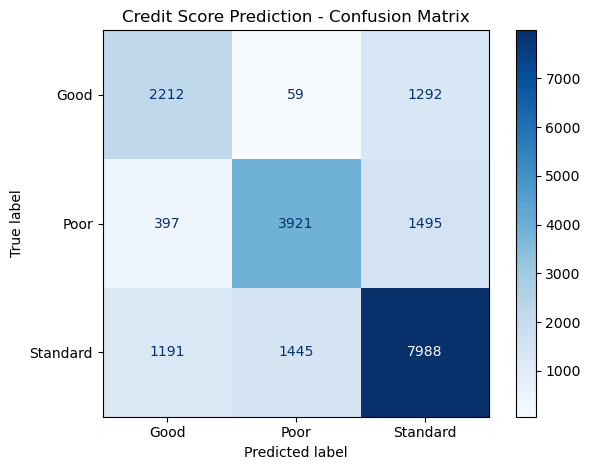

In [73]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)

plt.title("Credit Score Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()